# Research Intake 2026 — Day 32
# Advanced Object Detection & Tracking

**Module:** Computer Vision Fundamentals
**Source:** Gudsky Research Foundation — Research Intake 2026, Day 32

This notebook accompanies the Day 32 reading: extending Day 31's single-frame detection across time
into multi-object tracking, and from tracking into activity recognition. It closes with the full
**graded practical project, PP15** (implement and compare three activity-recognition approaches: 3D
CNN, two-stream, and skeleton/pose-based).

**How to use this notebook:** Sections 1–10 build every tracking mechanism with runnable code — a
from-scratch Kalman filter, IoU-based data association resolved via the Hungarian algorithm, a minimal
SORT tracker, and Siamese-tracker similarity matching — so the mechanics are visible, not hidden behind
a library call. The PP15 section then assembles all three activity-recognition architectures.


## 0. Environment Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

try:
    import torch
    import torch.nn as nn
    print("PyTorch version:", torch.__version__)
except ImportError:
    print("PyTorch not installed — install with: pip install torch")

try:
    from scipy.optimize import linear_sum_assignment
    print("scipy available (Hungarian algorithm)")
except ImportError:
    print("scipy not installed — install with: pip install scipy")

torch.manual_seed(0)
np.random.seed(0)


PyTorch version: 2.11.0+cu128
scipy available (Hungarian algorithm)


## 1. From Single-Frame Detection to Video

Day 31 answered "what objects are in this single image, and where?" The moment the input becomes a
video, a new question appears that detection alone cannot answer: is the car in frame 47 the same car
that was in frame 46? A detector's weights are fixed at inference time; its forward pass for frame 47
has literally no access to anything about frame 46 unless something external carries that information
across the frame boundary. **This day's organizing idea: detection (Day 31) + time = tracking, and
tracking + semantic interpretation = activity recognition** (this day's practical project).

**Why does naively running Day 31's detector independently on every frame not solve this?** A detector
with no memory of prior frames will, on some frames, miss an object it detected a moment ago (brief
occlusion, a confidence dip) and detect it again a few frames later — producing boxes that **flicker**
in and out of existence rather than a continuous, identity-preserving track. Any system counting
unique objects, measuring dwell time, or plotting a trajectory will produce wrong numbers if built on
flickering per-frame detections alone.


/tmp/ipykernel_759/797830059.py:13: UserWarning: You passed a edgecolor/edgecolors ('red') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  axes[0].scatter(true_positions[~detected_mask, 0], true_positions[~detected_mask, 1], c="none",


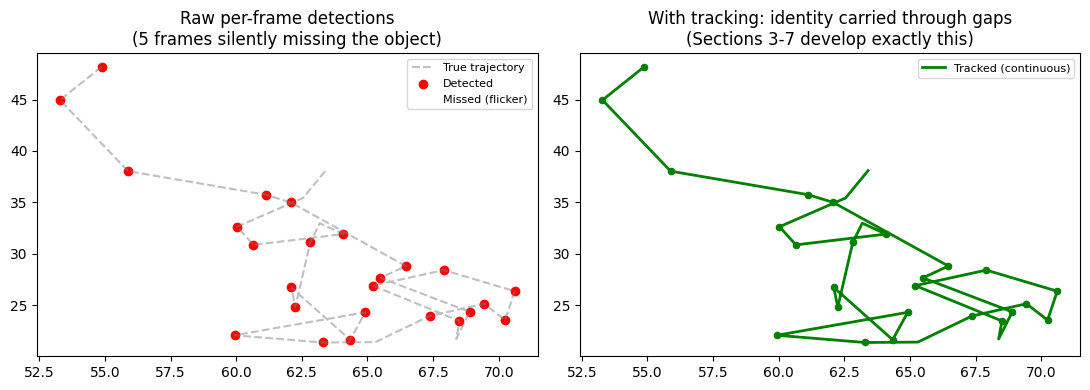

Detector missed the object on 5/30 frames.
Without tracking, any downstream counting/trajectory system built on these raw detections is wrong.


In [2]:
# Simulate the flicker problem directly: an object detected in most frames but missed in a few
np.random.seed(1)
n_frames = 30
true_positions = np.cumsum(np.random.randn(n_frames, 2) * 3, axis=0) + [50, 50]

# Simulate detection dropout: the detector misses the object on ~20% of frames
detected_mask = np.random.rand(n_frames) > 0.2
detected_frames = np.where(detected_mask)[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(true_positions[:, 0], true_positions[:, 1], "--", color="gray", alpha=0.5, label="True trajectory")
axes[0].scatter(true_positions[detected_mask, 0], true_positions[detected_mask, 1], c="red", label="Detected")
axes[0].scatter(true_positions[~detected_mask, 0], true_positions[~detected_mask, 1], c="none",
                 edgecolors="red", marker="x", s=80, label="Missed (flicker)")
axes[0].set_title(f"Raw per-frame detections\n({(~detected_mask).sum()} frames silently missing the object)")
axes[0].legend(fontsize=8)

axes[1].plot(true_positions[:, 0], true_positions[:, 1], "-", color="green", linewidth=2, label="Tracked (continuous)")
axes[1].scatter(true_positions[detected_mask, 0], true_positions[detected_mask, 1], c="green", s=20)
axes[1].set_title("With tracking: identity carried through gaps\n(Sections 3-7 develop exactly this)")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"Detector missed the object on {(~detected_mask).sum()}/{n_frames} frames.")
print("Without tracking, any downstream counting/trajectory system built on these raw detections is wrong.")


## 2. Advanced Detection Architectures (Brief Bridge from Day 31)

### 2.1 Anchor-free detectors — FCOS and CenterNet
Day 31 §7.2 flagged anchor design as a genuine trade-off. Anchor-free detectors sidestep it entirely.
**FCOS** predicts, for every pixel on a feature map, a direct regression to the four distances to an
object's box edges, plus a class label — no anchor boxes to design or tune. **CenterNet** predicts an
object's center as a peak on a heatmap, then regresses width/height directly — treating detection as
keypoint estimation. Both remove Day 31's anchor-design decision, simplifying the training pipeline, at
the cost of needing careful handling of ambiguous overlapping-object assignment.

### 2.2 DETR — a payoff, not a repeat
Day 31 §10.1 introduced DETR's set-prediction reframing. For this day's purposes: because DETR's output
is a clean, non-redundant set of predictions per frame, it removes one source of noise (duplicate,
NMS-dependent detections) that tracking-by-detection (§5) otherwise has to be robust against — a
genuine, if modest, advantage for tracking pipelines built on transformer-based detectors. This
shouldn't be overstated: DETR's slower training convergence applies whether it's a standalone detector
or the front end of a joint detect-and-track architecture. For PP15's compact scope, a well-established
YOLO or SSD (Day 31 §5–6) remains the more practical upstream detector.


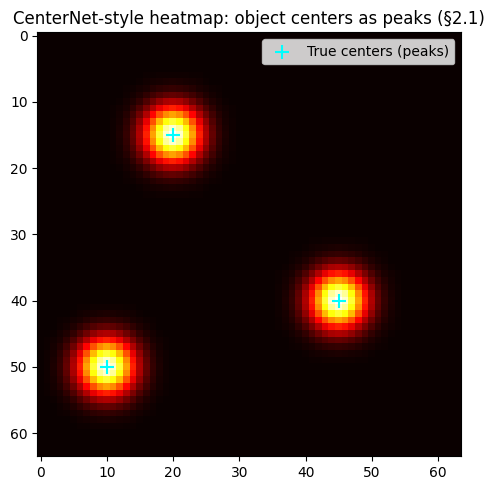

In [3]:
# Illustrate CenterNet's heatmap-based center prediction directly
def gaussian_heatmap(size, center, sigma=3):
    y, x = np.ogrid[:size, :size]
    return np.exp(-((x - center[0])**2 + (y - center[1])**2) / (2 * sigma**2))

heatmap = np.zeros((64, 64))
object_centers = [(20, 15), (45, 40), (10, 50)]
for cx, cy in object_centers:
    heatmap = np.maximum(heatmap, gaussian_heatmap(64, (cx, cy)))

plt.figure(figsize=(5, 5))
plt.imshow(heatmap, cmap="hot")
plt.scatter(*zip(*object_centers), c="cyan", marker="+", s=100, label="True centers (peaks)")
plt.title("CenterNet-style heatmap: object centers as peaks (§2.1)")
plt.legend()
plt.tight_layout(); plt.show()


## 3. The Object Tracking Problem

### 3.1 A formal definition — identity persistence across frames
Given a sequence of video frames, object tracking assigns each detected object a consistent identity
(a **track ID**) that persists correctly across every frame, even through brief occlusion, appearance
change, or missed detections. This is strictly harder than per-frame detection: a tracker must link
this frame's detection of a car to the same car's detection one frame earlier.

### 3.2 Single-Object Tracking (SOT) vs. Multi-Object Tracking (MOT)
**SOT** assumes a single target specified in the first frame; the tracker follows only that object.
**MOT** (this day's primary focus) tracks an unknown, potentially changing number of objects
simultaneously. SOT can afford a rich, per-target appearance model (§6.1's Siamese trackers); MOT
cannot afford this depth scaled to dozens of simultaneous objects within a real-time budget — which is
precisely why tracking-by-detection (§5) — cheap, detector-driven association — dominates MOT.

### 3.3 Core challenges — occlusion, appearance change, camera motion
**Occlusion** breaks the simplest strategy ("match to whatever is nearest next frame") outright —
Kalman filters (§4.2) and SORT (§5.4) exist substantially to handle this. **Appearance change**
(lighting, pose, partial occlusion) undermines pure visual-similarity matching — motivating learned
Re-ID embeddings (§6.2). **Camera motion** makes every object *appear* to move even when nothing is
actually moving — a confound detection never has to contend with, and one motion-only trackers (§4)
are particularly vulnerable to. Real footage rarely presents these challenges in isolation.


## 4. Classical Tracking Methods

The modern tracking landscape is layered, not binary: §4.2's Kalman filter is not a competitor to §6's
deep Re-ID embeddings — it's a component most deep tracking pipelines still use internally for motion
prediction (DeepSORT, §5.4's spotlight, illustrates exactly this).

### 4.1 Optical flow — Lucas-Kanade and Farneback
Optical flow estimates apparent motion of brightness patterns between consecutive frames. **Lucas-Kanade**
(sparse): tracks a small set of distinctive points, assuming brightness constancy and locally constant
motion within a small window. **Farneback** (dense): computes a motion vector for *every* pixel, via a
polynomial approximation of each neighborhood. Both share the **brightness constancy** assumption — a
weak point under fast lighting changes, reflective surfaces, or very large inter-frame motion.


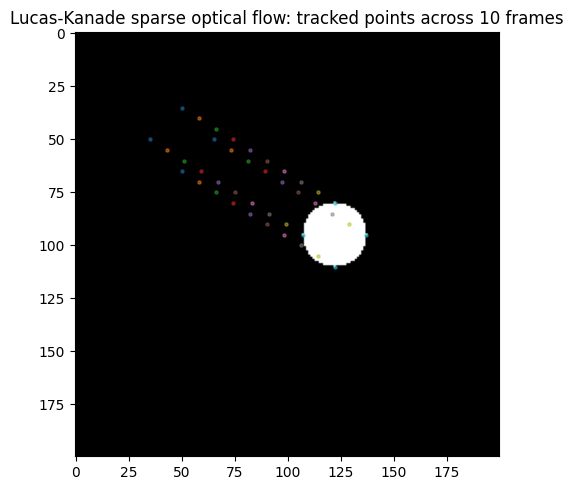

Each point's trajectory traces the object's apparent motion frame-to-frame (§4.1).


In [4]:
# Sparse (Lucas-Kanade) optical flow via OpenCV, on a synthetic moving-object video
try:
    import cv2

    def make_frame(size, center, radius=15):
        frame = np.zeros((size, size), dtype=np.uint8)
        cv2.circle(frame, center, radius, 255, -1)
        return frame

    size = 200
    centers = [(50 + i * 8, 50 + i * 5) for i in range(10)]
    frames = [make_frame(size, c) for c in centers]

    # Detect initial features to track (Shi-Tomasi corners, Day 28 §2.3)
    p0 = cv2.goodFeaturesToTrack(frames[0], maxCorners=20, qualityLevel=0.3, minDistance=7)

    lk_params = dict(winSize=(15, 15), maxLevel=2,
                      criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03))

    tracked_points = [p0]
    for i in range(1, len(frames)):
        p1, status, _ = cv2.calcOpticalFlowPyrLK(frames[i-1], frames[i], tracked_points[-1], None, **lk_params)
        tracked_points.append(p1)

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(frames[-1], cmap="gray")
    for pts in tracked_points:
        if pts is not None:
            ax.scatter(pts[:, 0, 0], pts[:, 0, 1], s=5, alpha=0.5)
    ax.set_title("Lucas-Kanade sparse optical flow: tracked points across 10 frames")
    plt.tight_layout(); plt.show()
    print("Each point's trajectory traces the object's apparent motion frame-to-frame (§4.1).")
except ImportError:
    print("OpenCV not installed — install with: pip install opencv-python-headless")


### 4.2 Kalman filters for state prediction
A Kalman filter maintains a running estimate of an object's state (position, velocity), updating it
each frame in two steps: a **prediction** step (project forward using a motion model) and a
**correction** step (adjust using the new frame's actual measurement, weighted by how much the filter
trusts the prediction vs. the measurement — the **Kalman gain**). This prediction step is what makes
Kalman filtering valuable for occlusion: during frames where an object is occluded and no detection is
available, the filter continues predicting from its last known motion.


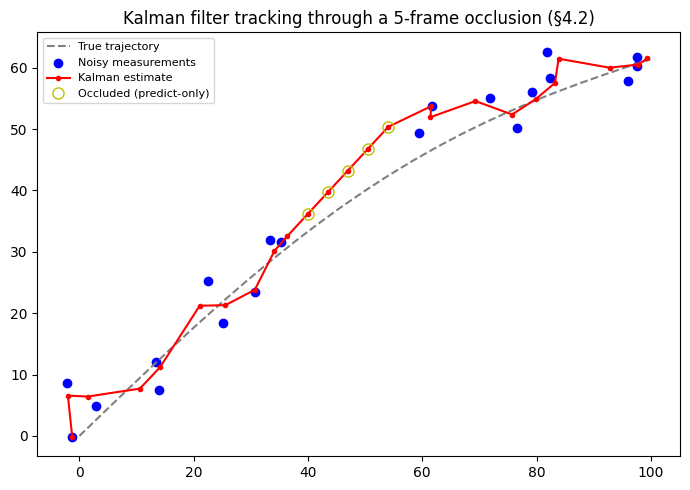

In [5]:
# A minimal, from-scratch 2D Kalman filter for position+velocity tracking (§4.2)
class SimpleKalmanFilter:
    def __init__(self, initial_position, dt=1.0, process_noise=1.0, measurement_noise=5.0):
        # State: [x, y, vx, vy]
        self.state = np.array([initial_position[0], initial_position[1], 0.0, 0.0])
        self.dt = dt
        self.F = np.array([  # motion model: position += velocity * dt
            [1, 0, dt, 0],
            [0, 1, 0, dt],
            [0, 0, 1, 0],
            [0, 0, 0, 1],
        ])
        self.H = np.array([  # we only measure position, not velocity
            [1, 0, 0, 0],
            [0, 1, 0, 0],
        ])
        self.P = np.eye(4) * 10  # state uncertainty
        self.Q = np.eye(4) * process_noise       # process noise
        self.R = np.eye(2) * measurement_noise   # measurement noise

    def predict(self):
        self.state = self.F @ self.state
        self.P = self.F @ self.P @ self.F.T + self.Q
        return self.state[:2]  # predicted position

    def correct(self, measurement):
        y = measurement - self.H @ self.state             # innovation
        S = self.H @ self.P @ self.H.T + self.R            # innovation covariance
        K = self.P @ self.H.T @ np.linalg.inv(S)            # Kalman gain
        self.state = self.state + K @ y
        self.P = (np.eye(4) - K @ self.H) @ self.P
        return self.state[:2]

# Simulate a moving object with a brief occlusion (missing measurements for a few frames)
np.random.seed(2)
n_frames = 25
true_traj = np.stack([np.linspace(0, 100, n_frames), np.linspace(0, 60, n_frames) + 10*np.sin(np.linspace(0,3,n_frames))], axis=1)
noisy_measurements = true_traj + np.random.randn(n_frames, 2) * 3
occluded_frames = set(range(10, 15))  # object occluded for 5 frames

kf = SimpleKalmanFilter(initial_position=noisy_measurements[0])
predicted_positions = []
for i in range(n_frames):
    pred = kf.predict()
    if i not in occluded_frames:
        pred = kf.correct(noisy_measurements[i])
    predicted_positions.append(pred.copy())
predicted_positions = np.array(predicted_positions)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(true_traj[:, 0], true_traj[:, 1], "--", color="gray", label="True trajectory")
visible = [i for i in range(n_frames) if i not in occluded_frames]
ax.scatter(noisy_measurements[visible, 0], noisy_measurements[visible, 1], c="blue", label="Noisy measurements")
ax.plot(predicted_positions[:, 0], predicted_positions[:, 1], "r-o", markersize=3, label="Kalman estimate")
occ_range = sorted(occluded_frames)
ax.plot(predicted_positions[occ_range, 0], predicted_positions[occ_range, 1], "yo", markersize=8,
        markerfacecolor="none", label="Occluded (predict-only)")
ax.set_title("Kalman filter tracking through a 5-frame occlusion (§4.2)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


### 4.3 Correlation filter trackers — MOSSE and KCF
Rather than modeling motion explicitly, correlation filter trackers learn a filter — updated online
frame by frame from the object's own appearance — producing a sharp correlation peak at the object's
location. **MOSSE**: extremely fast (hundreds of FPS), relatively brittle appearance modeling. **KCF**:
a kernel trick modeling a much richer implicit training set at similar speed. Both exploit that
correlation, expensive in the spatial domain, reduces to cheap element-wise multiplication in the
**frequency domain** (via FFT) — the source of their speed advantage over GPU-dependent deep trackers.

### 4.4 Why classical trackers remain relevant as fast baselines
**Rule of thumb:** correlation filter tracker (§4.3) for a single well-defined object under a severe
compute budget; SORT (§5.4) for multiple objects under a real-time budget with brief occlusions;
DeepSORT/Siamese/Re-ID (§5.4's spotlight, §6) specifically when crowded scenes or longer occlusions
make appearance information a practical necessity.


## 5. Detection-Based Tracking (Tracking-by-Detection)

### 5.1 The dominant modern paradigm
Run Day 31's detector independently on every frame, then solve a separate **data association**
problem — deciding which detections correspond to which existing tracks — using previous frames' track
states as context. This cleanly separates detection quality from association quality, echoing Day 31's
backbone-plus-head framing one level up. Because the two halves are decoupled, either can be improved
independently — upgrading the detector improves tracking without touching association logic; upgrading
association (SORT → DeepSORT) improves tracking without retraining the detector.

### 5.2 The data association problem and IoU-based matching
Given existing tracks (each with a Kalman-predicted location) and fresh detections, which detection
corresponds to which track? The simplest similarity measure is **IoU** between a track's predicted box
and each candidate detection — computed here between prediction and detection, not prediction and
ground truth as in Day 31. A detection with no sufficiently high-IoU match starts a new **tentative**
track (requiring several consecutive matches before confirmation, so a stray false positive doesn't
spawn a permanent identity). A track with no matching detection **coasts** on its Kalman prediction for
some frames before being dropped.


In [6]:
# IoU-based cost matrix between predicted track positions and fresh detections (§5.2)
def compute_iou(box_a, box_b):
    x1, y1 = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
    x2, y2 = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
    intersection = max(0, x2-x1) * max(0, y2-y1)
    area_a = (box_a[2]-box_a[0]) * (box_a[3]-box_a[1])
    area_b = (box_b[2]-box_b[0]) * (box_b[3]-box_b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0

# Simulate 3 existing tracks (predicted boxes) and 3 fresh detections in the current frame
track_predictions = [(10, 10, 50, 50), (100, 100, 140, 140), (200, 50, 240, 90)]
detections = [(12, 12, 52, 52), (205, 55, 245, 95), (300, 300, 340, 340)]  # 3rd is a new object

cost_matrix = np.zeros((len(track_predictions), len(detections)))
for i, track_box in enumerate(track_predictions):
    for j, det_box in enumerate(detections):
        cost_matrix[i, j] = 1 - compute_iou(track_box, det_box)  # lower cost = better match

print("Cost matrix (1 - IoU), rows=tracks, cols=detections:")
print(np.round(cost_matrix, 3))


Cost matrix (1 - IoU), rows=tracks, cols=detections:
[[0.178 1.    1.   ]
 [1.    1.    1.   ]
 [1.    0.38  1.   ]]


### 5.3 The Hungarian algorithm for optimal assignment
Simply assigning each track to its individually highest-IoU detection greedily can produce inconsistent
results — two tracks might both prefer the same detection. The **Hungarian algorithm** finds the
globally optimal one-to-one assignment minimizing total cost across the whole matrix — the same
algorithm Day 31 §10.1 previewed from DETR's training-time bipartite matching, now used for
track-to-detection assignment at inference time. Combined with a hard cost threshold: even the best
available match is rejected if its cost exceeds a threshold, preventing a forced obviously-wrong match.


In [7]:
from scipy.optimize import linear_sum_assignment

track_indices, det_indices = linear_sum_assignment(cost_matrix)

MAX_COST_THRESHOLD = 0.7  # reject matches with IoU below 0.3

print("Hungarian algorithm's optimal assignment (§5.3):")
matched_pairs = []
for t, d in zip(track_indices, det_indices):
    cost = cost_matrix[t, d]
    if cost <= MAX_COST_THRESHOLD:
        matched_pairs.append((t, d))
        print(f"  Track {t} <-> Detection {d}  (IoU={1-cost:.3f}) -> MATCHED")
    else:
        print(f"  Track {t} <-> Detection {d}  (IoU={1-cost:.3f}) -> REJECTED (below threshold)")

unmatched_detections = set(range(len(detections))) - {d for _, d in matched_pairs}
print(f"\nUnmatched detections (candidate new tracks, §5.2): {unmatched_detections}")


Hungarian algorithm's optimal assignment (§5.3):
  Track 0 <-> Detection 0  (IoU=0.822) -> MATCHED
  Track 1 <-> Detection 2  (IoU=0.000) -> REJECTED (below threshold)
  Track 2 <-> Detection 1  (IoU=0.620) -> MATCHED

Unmatched detections (candidate new tracks, §5.2): {2}


### 5.4 SORT — a minimal baseline
SORT (Simple Online and Realtime Tracking) combines exactly §4.2, §5.2, and §5.3's three ingredients —
a Kalman filter per track, IoU as the sole association measure, and the Hungarian algorithm — into a
complete, minimal, extremely fast tracker with **no learned appearance model at all**. Its central
limitation: matching purely on motion and box overlap struggles through long occlusions and in crowded
scenes with similar-looking, closely-spaced objects.

**Research Spotlight — DeepSORT:** extends SORT with exactly the fix SORT's limitation points toward —
a learned appearance embedding (§6.2's Re-ID feature) combined with the Kalman-filter motion cost when
building the association cost matrix, substantially improving robustness through occlusion and in
crowded scenes.


In [8]:
# A complete minimal SORT tracker, combining Kalman filtering + IoU + Hungarian assignment
class Track:
    _next_id = 0
    def __init__(self, initial_box):
        self.id = Track._next_id; Track._next_id += 1
        cx, cy = (initial_box[0]+initial_box[2])/2, (initial_box[1]+initial_box[3])/2
        self.kf = SimpleKalmanFilter((cx, cy))
        self.w = initial_box[2] - initial_box[0]
        self.h = initial_box[3] - initial_box[1]
        self.confirmed_hits = 1
        self.missed_frames = 0
        self.confirmed = False

    def predicted_box(self):
        cx, cy = self.kf.predict()
        return (cx - self.w/2, cy - self.h/2, cx + self.w/2, cy + self.h/2)

    def update(self, box):
        cx, cy = (box[0]+box[2])/2, (box[1]+box[3])/2
        self.kf.correct(np.array([cx, cy]))
        self.w, self.h = box[2]-box[0], box[3]-box[1]
        self.confirmed_hits += 1
        self.missed_frames = 0
        if self.confirmed_hits >= 3:
            self.confirmed = True

class SimpleSORT:
    def __init__(self, iou_threshold=0.3, max_missed=5, min_hits=3):
        self.tracks = []
        self.iou_threshold = iou_threshold
        self.max_missed = max_missed
        self.min_hits = min_hits

    def step(self, detections):
        predicted = [t.predicted_box() for t in self.tracks]
        if predicted and detections:
            cost = np.array([[1 - compute_iou(p, d) for d in detections] for p in predicted])
            row_idx, col_idx = linear_sum_assignment(cost)
            matched_tracks, matched_dets = set(), set()
            for r, c in zip(row_idx, col_idx):
                if cost[r, c] <= (1 - self.iou_threshold):
                    self.tracks[r].update(detections[c])
                    matched_tracks.add(r); matched_dets.add(c)
        else:
            matched_tracks, matched_dets = set(), set()

        for i, t in enumerate(self.tracks):
            if i not in matched_tracks:
                t.missed_frames += 1

        for j, d in enumerate(detections):
            if j not in matched_dets:
                self.tracks.append(Track(d))

        self.tracks = [t for t in self.tracks if t.missed_frames <= self.max_missed]
        return [(t.id, t.predicted_box()) for t in self.tracks if t.confirmed]

tracker = SimpleSORT()
# Simulate a 15-frame sequence with one object, briefly undetected mid-sequence
np.random.seed(3)
object_path = [(20+i*5, 20+i*3, 60+i*5, 60+i*3) for i in range(15)]
detection_sequence = [box if i not in (6, 7, 8) else [] for i, box in enumerate(object_path)]

print("Frame | Confirmed tracks (id, box)")
for i, dets in enumerate(detection_sequence):
    dets_list = [dets] if dets else []
    confirmed = tracker.step(dets_list)
    print(f"{i:>5} | {[(tid, tuple(round(v,1) for v in box)) for tid, box in confirmed]}")

print("\nNotice: the SAME track ID persists through frames 6-8's missing detections (§4.2's coasting),")
print("rather than the track being dropped and a new ID being spawned upon re-detection.")


Frame | Confirmed tracks (id, box)
    0 | []
    1 | []
    2 | [(0, (np.float64(32.7), np.float64(27.6), np.float64(72.7), np.float64(67.6)))]
    3 | [(0, (np.float64(38.4), np.float64(31.1), np.float64(78.4), np.float64(71.1)))]
    4 | [(0, (np.float64(43.1), np.float64(33.8), np.float64(83.1), np.float64(73.8)))]
    5 | [(0, (np.float64(47.7), np.float64(36.6), np.float64(87.7), np.float64(76.6)))]
    6 | [(0, (np.float64(52.8), np.float64(39.7), np.float64(92.8), np.float64(79.7)))]
    7 | [(0, (np.float64(58.0), np.float64(42.8), np.float64(98.0), np.float64(82.8)))]
    8 | [(0, (np.float64(63.1), np.float64(45.8), np.float64(103.1), np.float64(85.8)))]
    9 | [(0, (np.float64(67.5), np.float64(48.5), np.float64(107.5), np.float64(88.5)))]
   10 | [(0, (np.float64(72.5), np.float64(51.5), np.float64(112.5), np.float64(91.5)))]
   11 | [(0, (np.float64(77.5), np.float64(54.5), np.float64(117.5), np.float64(94.5)))]
   12 | [(0, (np.float64(82.5), np.float64(57.5), np.float6

## 6. Deep Learning Trackers

Section 5's DeepSORT spotlight already previewed this section's core idea: learned, appearance-based
similarity, rather than motion and box geometry alone, as the primary signal for maintaining identity.

### 6.1 Siamese network trackers
Two identical, weight-sharing CNN branches: one encodes a template crop of the target object, the other
encodes a larger search region in the current frame. The two representations are compared (commonly via
cross-correlation) to produce a similarity map; the highest-similarity location is the object's new
position. Because both branches share weights, the network learns a single embedding space where
matching crops of the *same object instance* land close together — this is what lets a Siamese tracker
generalize to objects it never saw labeled examples of during training: it solves a category-agnostic
similarity problem, not a fixed-category classification problem.


Similarity map shape: torch.Size([1, 1, 33, 33])
Peak similarity location (the tracked object's new position): (27, 11)


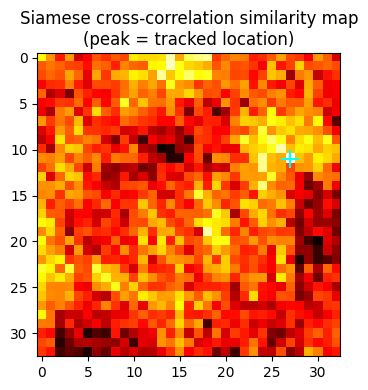

In [9]:
# A minimal Siamese tracker: shared-weight CNN branches + cross-correlation similarity
class SiameseBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 5), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 5), nn.ReLU(),
        )
    def forward(self, x):
        return self.net(x)

class SiameseTracker(nn.Module):
    def __init__(self):
        super().__init__()
        self.branch = SiameseBranch()  # SAME weights used for both template and search region

    def forward(self, template, search_region):
        template_feat = self.branch(template)     # (B, C, h, w) -- small
        search_feat = self.branch(search_region)   # (B, C, H, W) -- larger

        # Cross-correlation: slide the template feature as a kernel over the search feature
        B, C, h, w = template_feat.shape
        similarity_maps = []
        for b in range(B):
            kernel = template_feat[b:b+1]              # (1, C, h, w)
            response = torch.nn.functional.conv2d(search_feat[b:b+1], kernel)
            similarity_maps.append(response)
        return torch.cat(similarity_maps, dim=0)  # (B, 1, out_h, out_w)

siamese = SiameseTracker()
template_crop = torch.randn(1, 3, 32, 32)   # tight crop around the target (e.g., from frame 1)
search_region = torch.randn(1, 3, 96, 96)   # larger crop centered on expected location (current frame)

similarity_map = siamese(template_crop, search_region)
peak_idx = similarity_map[0, 0].argmax()
peak_y, peak_x = np.unravel_index(peak_idx.item(), similarity_map.shape[2:])

print(f"Similarity map shape: {similarity_map.shape}")
print(f"Peak similarity location (the tracked object's new position): ({peak_x}, {peak_y})")

plt.figure(figsize=(4, 4))
plt.imshow(similarity_map[0, 0].detach().numpy(), cmap="hot")
plt.scatter([peak_x], [peak_y], c="cyan", marker="+", s=150)
plt.title("Siamese cross-correlation similarity map\n(peak = tracked location)")
plt.tight_layout(); plt.show()


### 6.2 Re-Identification (Re-ID) embeddings
Trained with a more explicit, MOT-specific objective: given two crops, output embeddings such that
crops of the same object instance land close together and crops of different objects land far apart —
typically trained with a metric-learning loss (e.g., triplet loss) across many identities. A Re-ID
embedding succeeds where raw IoU fails: IoU only measures spatial overlap, which breaks down whenever a
track's motion prediction is even moderately wrong; a Re-ID embedding measures what the object actually
looks like, remaining valid even when predicted location has drifted substantially.


In [10]:
# Triplet loss: the standard training objective for Re-ID embeddings (§6.2)
def triplet_loss(anchor, positive, negative, margin=1.0):
    """anchor & positive: same identity; anchor & negative: different identities.
    Pulls anchor-positive distance down, pushes anchor-negative distance up."""
    pos_dist = torch.nn.functional.pairwise_distance(anchor, positive)
    neg_dist = torch.nn.functional.pairwise_distance(anchor, negative)
    return torch.clamp(pos_dist - neg_dist + margin, min=0).mean()

# Simulated embeddings: anchor+positive close together, negative far away (a well-trained state)
anchor_emb = torch.tensor([[1.0, 2.0, 0.5]])
positive_emb = torch.tensor([[1.1, 1.9, 0.6]])   # same identity, slightly different crop
negative_emb = torch.tensor([[5.0, -1.0, 3.0]])  # different identity

loss = triplet_loss(anchor_emb, positive_emb, negative_emb)
print(f"Triplet loss (well-separated embeddings): {loss.item():.4f}  (near zero -> good separation)")

# A poorly-trained state: negative accidentally close to anchor
bad_negative_emb = torch.tensor([[1.05, 2.05, 0.55]])
bad_loss = triplet_loss(anchor_emb, positive_emb, bad_negative_emb)
print(f"Triplet loss (negative too close to anchor): {bad_loss.item():.4f}  (higher -> needs more training)")


Triplet loss (well-separated embeddings): 0.0000  (near zero -> good separation)
Triplet loss (negative too close to anchor): 1.0866  (higher -> needs more training)


### 6.3 End-to-end detect-and-track transformers
The most recent research collapses §5–6's separate detect-then-associate pipeline into a single,
jointly trained transformer performing detection and association together, extending Day 31 §10.1's
DETR framing across time via persistent **track queries**. This is a concrete instance of the general
trend: hand-designed pipeline stages (the Hungarian algorithm) progressively giving way to a single
learned network. The trade-off: these joint architectures generally require substantially more training
data and compute than tracking-by-detection's modular pipeline. For PP15's compact scope,
tracking-by-detection remains the more tractable choice.


## 7. Multi-Object Tracking (MOT) Evaluation

### 7.1 MOT-specific metrics — MOTA, MOTP, IDF1, and ID switches
Day 31's mAP measures detection accuracy per frame in isolation and cannot penalize a tracker for
losing an object's identity. **MOTA** combines missed detections, false positives, and identity
switches into one accuracy-style score. **MOTP** separately measures localization precision of
correctly matched detections. **IDF1** measures how well predicted tracks correspond to ground-truth
identities across the *entire sequence*, weighting identity consistency more heavily than MOTA — the
more informative metric when preserving correct identity matters most (PP15's situation). **ID
switches** count a tracking-specific failure with no detection-only analogue: the number of times a
single ground-truth object's assigned track ID changes across the sequence.

**Both MOTA and IDF1 should be reported together** — a tracker can achieve high MOTA (strong per-frame
detection) while switching identities often in crowded segments (lower IDF1); reporting only one hides
exactly this trade-off, echoing Day 31 §3.4's AP@0.5-vs-AP@[0.5:0.95] caution.


In [11]:
# A from-scratch ID-switch counter, directly illustrating what MOTA/IDF1 penalize that mAP cannot
def count_id_switches(ground_truth_ids, predicted_ids):
    """Both are lists of the same length -- the assigned ID at each frame for one real object."""
    switches = 0
    for i in range(1, len(predicted_ids)):
        if predicted_ids[i] != predicted_ids[i-1] and predicted_ids[i-1] is not None and predicted_ids[i] is not None:
            switches += 1
    return switches

# Scenario: a tracker that flickers identity across a crowded segment
predicted_track_ids = [1, 1, 1, 1, 2, 2, 1, 1, 1, 3, 3, 3]  # IDs 1 and 2 both refer to the SAME real object
n_switches = count_id_switches(None, predicted_track_ids)

print(f"Predicted track ID sequence for one real object: {predicted_track_ids}")
print(f"ID switches: {n_switches}")
print("\nA per-frame detection metric (mAP) would see every frame as a 'correct detection' if the box")
print("location was right each time -- it has NO way to penalize the identity flicker above. This is")
print("exactly why MOT needs its own metric family (§7.1).")


Predicted track ID sequence for one real object: [1, 1, 1, 1, 2, 2, 1, 1, 1, 3, 3, 3]
ID switches: 3

A per-frame detection metric (mAP) would see every frame as a 'correct detection' if the box
location was right each time -- it has NO way to penalize the identity flicker above. This is
exactly why MOT needs its own metric family (§7.1).


### 7.2 Standard MOT benchmarks
The **MOTChallenge** benchmark suite (MOT16, MOT17, MOT20) provides fixed video sequences with
ground-truth annotated tracks for matched-condition comparison — the same fairness principle Day 31
§8.3 established for YOLO-vs-SSD, applied to tracking algorithms. Successive releases increased scene
density: MOT16/17 use moderately crowded pedestrian scenes; MOT20 targets very high-density crowds. A
strong score on MOT16 does not predict similarly strong performance on MOT20.

### 7.3 Practical challenges at scale
Crowded scenes push IoU-ambiguity and appearance-similarity limits to their extreme. Long-term occlusion
tests whether Re-ID (§6.2) is strong enough to correctly re-link a reappearing object rather than
silently starting a new track. Computational cost scales with the number of tracks and detections (cost
matrix construction, Hungarian resolution, Re-ID embedding computation per detection per frame) — a
pipeline comfortable with ten tracks may struggle to maintain real-time performance with a hundred.


## 8. From Tracking to Activity Recognition

Once an object — typically a person — has a tracked trajectory across time, what is it *doing*?
Per-frame classification (Day 29) cannot answer this alone: many actions are only distinguishable by
their temporal pattern. A single frame of someone with a bent knee could be a jump, squat, or standing
awkwardly — only the sequence across frames resolves the ambiguity.

### 8.1 Why activity recognition needs temporal context
Three design answers to "how should information be aggregated across the frame sequence?":
- **3D CNNs** (C3D, I3D) — 3D convolutions slide across height, width, *and time* simultaneously,
  learning spatiotemporal filters directly.
- **CNN+LSTM/RNN** — a 2D CNN encodes each frame independently, a recurrent network then processes the
  resulting sequence of feature vectors, explicitly modeling how they evolve over time.
- **Video transformers** — replace recurrent aggregation with self-attention across the frame sequence.

**Concrete motivating example:** distinguishing "sitting down" from "standing up" from a single,
arbitrarily-chosen frame is close to impossible if that frame catches the midpoint of either action —
only the *direction* of change across consecutive frames resolves it.


### 8.2 Approaches to activity recognition — the three-way comparison PP15 requires

- **3D CNN (C3D/I3D)** — treats a short clip as a spatiotemporal volume, learns motion features directly
  through 3D convolutions, no separate preprocessing — but meaningfully higher compute cost (3D kernels
  are substantially more expensive than 2D) and needs more training data.
- **Two-stream** — a spatial stream (raw RGB frames) + a temporal stream (dense optical flow, §4.1)
  fused at the end — historically a strong baseline since optical flow hands the temporal stream an
  explicit motion signal rather than requiring the network to discover motion patterns unsupervised, at
  the cost of optical flow computation becoming a preprocessing bottleneck.
- **Skeleton/pose-based** — extracts human pose keypoints per frame via a pretrained pose estimator,
  then classifies the resulting keypoint trajectory sequence — by far the lightest compute cost, most
  robust to background/appearance variation, but discards any information not captured by joint
  positions (can't distinguish "drinking from a cup" vs. "holding a phone to the ear," which produce
  near-identical arm-joint trajectories).

No approach dominates on all axes — no universal winner, only a fit for the compute budget, data
availability, and the specific actions being classified.


In [12]:
import torch.nn as nn

# ---- Approach A: 3D CNN (C3D/I3D-style) ----
class Simple3DCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv3d(3, 16, kernel_size=(3, 3, 3), padding=1),   # convolves over (time, height, width)
            nn.ReLU(), nn.MaxPool3d((1, 2, 2)),
            nn.Conv3d(16, 32, kernel_size=(3, 3, 3), padding=1),
            nn.ReLU(), nn.MaxPool3d((2, 2, 2)),
        )
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool3d(1), nn.Flatten(), nn.Linear(32, num_classes))

    def forward(self, x):
        # x shape: (batch, channels=3, time, height, width)
        return self.classifier(self.features(x))

model_3dcnn = Simple3DCNN(num_classes=5)
clip = torch.randn(2, 3, 16, 64, 64)  # 2 clips, 16 frames each, 64x64 RGB
out_3dcnn = model_3dcnn(clip)
print(f"3D CNN: input clip {clip.shape} -> output {out_3dcnn.shape}")
print(f"3D CNN parameters: {sum(p.numel() for p in model_3dcnn.parameters()):,}")


3D CNN: input clip torch.Size([2, 3, 16, 64, 64]) -> output torch.Size([2, 5])
3D CNN parameters: 15,333


In [13]:
# ---- Approach B: Two-Stream (spatial RGB + temporal optical flow), late fusion ----
class TwoStreamNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        def make_stream(in_channels):
            return nn.Sequential(
                nn.Conv2d(in_channels, 16, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
                nn.Conv2d(16, 32, 5, padding=2), nn.ReLU(),
                nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            )
        self.spatial_stream = make_stream(in_channels=3)   # a single RGB frame
        self.temporal_stream = make_stream(in_channels=2)  # stacked optical-flow (x,y) channels
        self.spatial_fc = nn.Linear(32, num_classes)
        self.temporal_fc = nn.Linear(32, num_classes)

    def forward(self, rgb_frame, flow_field):
        spatial_logits = self.spatial_fc(self.spatial_stream(rgb_frame))
        temporal_logits = self.temporal_fc(self.temporal_stream(flow_field))
        return (spatial_logits + temporal_logits) / 2  # late fusion (§8.2): average final scores

model_2stream = TwoStreamNet(num_classes=5)
rgb_input = torch.randn(2, 3, 64, 64)     # a single representative RGB frame per clip
flow_input = torch.randn(2, 2, 64, 64)    # dense optical flow (2 channels: horizontal + vertical motion)

out_2stream = model_2stream(rgb_input, flow_input)
print(f"Two-Stream: RGB {rgb_input.shape} + flow {flow_input.shape} -> output {out_2stream.shape}")
print(f"Two-Stream parameters: {sum(p.numel() for p in model_2stream.parameters()):,}")


Two-Stream: RGB torch.Size([2, 3, 64, 64]) + flow torch.Size([2, 2, 64, 64]) -> output torch.Size([2, 5])
Two-Stream parameters: 28,026


In [14]:
# ---- Approach C: Skeleton/pose-based ----
# Classifies a sequence of extracted 2D keypoints (e.g. 17 COCO-style joints) rather than raw pixels
class SkeletonClassifier(nn.Module):
    def __init__(self, n_joints=17, hidden_size=64, num_classes=5):
        super().__init__()
        self.rnn = nn.LSTM(input_size=n_joints * 2, hidden_size=hidden_size, batch_first=True)
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, keypoint_sequence):
        # keypoint_sequence shape: (batch, n_frames, n_joints * 2)  -- (x,y) per joint, flattened
        _, (h_n, _) = self.rnn(keypoint_sequence)
        return self.classifier(h_n[-1])

model_skeleton = SkeletonClassifier(n_joints=17, num_classes=5)
keypoints = torch.randn(2, 16, 17 * 2)  # 2 clips, 16 frames, 17 joints x (x,y)

out_skeleton = model_skeleton(keypoints)
print(f"Skeleton-based: input {keypoints.shape} -> output {out_skeleton.shape}")
print(f"Skeleton-based parameters: {sum(p.numel() for p in model_skeleton.parameters()):,}")

print("\n--- Parameter count comparison (a direct proxy for compute cost, §8.2) ---")
for name, model in [("3D CNN", model_3dcnn), ("Two-Stream", model_2stream), ("Skeleton-based", model_skeleton)]:
    print(f"{name:>15}: {sum(p.numel() for p in model.parameters()):>10,} parameters")


Skeleton-based: input torch.Size([2, 16, 34]) -> output torch.Size([2, 5])
Skeleton-based parameters: 25,925

--- Parameter count comparison (a direct proxy for compute cost, §8.2) ---
         3D CNN:     15,333 parameters
     Two-Stream:     28,026 parameters
 Skeleton-based:     25,925 parameters


## 9. Real-World Applications

Every application below is ultimately a cost-benefit calculation between how much tracking and
activity-recognition accuracy a deployment needs and how much latency, compute, or privacy intrusion it
can tolerate — the same calculus Day 31 §9 traced for detection alone, now with a third axis (identity
persistence quality, §7's metrics) added.

- **Sports analytics** — tracking every player and the ball for tactical analysis, highlight generation.
  Relatively few, well-separated players, though set pieces and goalmouth scrambles push crowded-scene
  challenges. Skeleton-based recognition (§8.2) tends to be a strong fit here, given broadcast footage's
  variable camera angles and crowd backgrounds.
- **Autonomous driving** — tracking adds motion prediction ("where will this pedestrian be next") on
  top of raw detection. Sudden, discontinuous appearance from occlusion (a pedestrian stepping from
  behind a parked vehicle) is a specific difficulty sports analytics largely doesn't face.
- **Retail behavior analysis** — following shoppers' movement for traffic patterns, dwell time. A
  motion-only SORT-style tracker with no Re-ID (§6.2) is meaningfully less privacy-invasive than one
  adding persistent Re-ID — a genuine architectural choice with real privacy consequences.
- **Healthcare** — fall detection, mobility/activity monitoring without continuous staff observation.
  Raises consent and dignity questions beyond public-space surveillance (a patient's private room).
- **Security and surveillance** — tracking and activity recognition intensify Day 31 §9.4's surveillance
  concern directly: an individual's full trajectory *and* what they're doing at each point produces a
  substantially richer behavioral profile than static detection alone.


## 10. Research Frontiers

- **End-to-end detect-track-recognize pipelines** — extending §6.3's joint detection-and-association
  transformers one step further, letting gradient signal from an activity label improve the upstream
  tracking behavior itself, rather than treating activity recognition as a separate stage operating on
  already-tracked trajectories.
- **Self-supervised video representation learning** — addresses the cost of labeled video data
  (annotating tracked identities and activity labels frame by frame is far more expensive than Day 29's
  image-level labels) via pretext tasks requiring no manual annotation (predicting a shuffled frame
  sequence's correct order, tracking a region consistently across frames with no identity labels).
- **Multi-camera, multi-view tracking** — maintaining a single consistent identity as an object moves
  between multiple cameras' fields of view — a genuinely harder version of §6.2's Re-ID problem.
- **Forward reference to Day 33** — this day extended detection across *time* (identity, same bounding
  box representation); Day 33 extends detection across *space* (a precise pixel boundary, same frame).
  The two converge in **video object segmentation**, tracking a mask rather than a box across frames.


## 11. Common Pitfalls: A Practical Debugging Checklist

1. **Visualize tracked trajectories overlaid on the actual video before trusting any MOT metric** — an
   ID-switch count or MOTA score alone can hide a track silently jumping between two different real
   objects.
2. **Confirm the detector feeding your tracker is itself producing stable, high-confidence detections**
   — a tracking-by-detection pipeline's quality is capped by its upstream detector; many apparent
   tracking bugs are actually Day 31-level detection issues surfacing downstream.
3. **Check whether IoU-only matching is failing specifically in occlusion-heavy or crowded segments
   before assuming a bug** — this is SORT's known, expected weak point (§5.4), not necessarily an
   implementation error.
4. **Verify optical flow is actually being computed correctly before trusting a two-stream result** — a
   silently degenerate flow field (e.g., all-zero vectors from a preprocessing bug) starves the temporal
   stream, producing a model that appears to train while relying entirely on the spatial stream.
5. **Watch for class imbalance across action categories skewing accuracy** — check per-class accuracy,
   not only the averaged metric.
6. **Watch for a track-confirmation threshold set too low or too high** — too low, stray false positives
   spawn phantom tracks; too high, genuinely new objects take longer to be confirmed.


In [15]:
# Demonstrate pitfall #4 directly: a degenerate (all-zero) optical flow field starving the temporal stream
degenerate_flow = torch.zeros(2, 2, 64, 64)  # bug: flow computation silently returned all zeros

out_degenerate = model_2stream(rgb_input, degenerate_flow)
temporal_contribution = model_2stream.temporal_fc(model_2stream.temporal_stream(degenerate_flow))

print("With a healthy flow field, temporal stream logits vary meaningfully across the batch:")
print(model_2stream.temporal_fc(model_2stream.temporal_stream(flow_input)).detach().numpy().round(3))
print("\nWith a degenerate (all-zero) flow field, temporal stream logits collapse to a constant:")
print(temporal_contribution.detach().numpy().round(3))
print("\nThis is the silent failure mode §11's checklist warns about: training will still 'work'")
print("(loss decreases) because the spatial stream still carries signal, but the model has learned")
print("nothing from motion at all -- easy to miss without explicitly inspecting the flow field itself.")


With a healthy flow field, temporal stream logits vary meaningfully across the batch:
[[-0.056  0.138 -0.006  0.169 -0.002]
 [-0.057  0.142 -0.004  0.167 -0.004]]

With a degenerate (all-zero) flow field, temporal stream logits collapse to a constant:
[[-0.011 -0.022  0.103  0.056  0.011]
 [-0.011 -0.022  0.103  0.056  0.011]]

This is the silent failure mode §11's checklist warns about: training will still 'work'
(loss decreases) because the spatial stream still carries signal, but the model has learned
nothing from motion at all -- easy to miss without explicitly inspecting the flow field itself.


### 11.1 A note on reproducibility
Tracking and activity recognition introduce further randomness sources beyond weight initialization and
augmentation: the Hungarian algorithm's assignment is deterministic given its cost matrix, but the cost
matrix depends on the upstream detector's confidence-threshold and NMS randomness where ties occur, and
§8's temporal-model training involves the same stochastic optimization sources as any deep network. For
PP15's three-way comparison, fix random seeds across all three approaches' training runs explicitly.

### 11.2 A note on comparing against published benchmarks
Published MOTChallenge or academic action-recognition benchmark figures use full-scale datasets and
extensive training budgets — a PP15 result considerably lower than a published figure is expected, not
necessarily an implementation problem. The meaningful comparison is always the three PP15 approaches
against each other under your own matched conditions.


## Glossary of Terms

| Term | Definition |
|---|---|
| Track confirmation | Requiring several consecutive detections before a tentative track is fully established (§5.2) |
| Track coasting | Continuing to predict a track's position from Kalman motion after a missed detection, before dropping it (§5.2) |
| Tracking-by-detection | The dominant MOT paradigm: detect every frame, solve association separately (§5.1) |
| Data association | Deciding which of a new frame's detections correspond to which existing tracks (§5.2) |
| Hungarian algorithm | An optimal-assignment algorithm resolving a cost matrix into the globally best one-to-one matching (§5.3) |
| Kalman filter | A predict-then-correct state estimator, valuable through brief occlusions (§4.2) |
| Correlation filter tracker | A tracker learning an online-updated filter peaking at the object's location via frequency-domain computation (§4.3) |
| Re-ID embedding | A learned appearance representation making association robust to occlusion/crowding (§6.2) |
| MOTA / MOTP / IDF1 | The core MOT evaluation metric family (§7.1) |
| ID switch | A single ground-truth object's assigned track ID changing incorrectly mid-sequence (§7.1) |
| Siamese tracker | Two weight-sharing CNN branches comparing a template crop against a search region (§6.1) |
| 3D CNN (C3D/I3D) | Applying 3D convolutions across height, width, and time directly, at high compute cost (§8.2) |
| Two-stream network | Fusing a spatial RGB stream with a temporal optical-flow stream (§8.2) |
| Skeleton/pose-based recognition | Classifying extracted pose keypoint sequences, lightweight but blind to object interactions (§8.2) |

---
## Chapter Summary: Key Takeaways

- Tracking is detection (Day 31) plus identity persistence across time; naive independent per-frame
  detection produces flicker, not stable tracks (§1).
- Tracking-by-detection dominates modern practice: detect every frame, solve data association — IoU
  cost matrix resolved by the Hungarian algorithm — as a separate step (§5.1–5.3).
- Kalman filters predict through occlusion; learned Re-ID embeddings (DeepSORT) add appearance
  robustness IoU alone cannot provide (§4.2, §6.2).
- Classical correlation-filter trackers remain the right choice under a hard compute budget (§4.3–4.4).
- MOT needs its own metrics — MOTA, MOTP, IDF1, and ID switches — because per-frame detection accuracy
  cannot penalize identity loss (§7.1).
- Activity recognition needs genuine temporal modeling; per-frame classification alone cannot
  disambiguate actions that only differ across a sequence (§8.1).
- The three PP15 approaches trade compute cost, data requirement, and robustness against each other,
  with no universal winner (§8.2).
- This day extends detection across time; Day 33 extends it across space — the two converge in video
  object segmentation (§10).


---
# Assignment / Practical Project Brief

## PP15: Video Activity Recognition

**★ GRADED ASSIGNMENT**

The core requirement: implement all three activity-recognition approaches from §8.2 — 3D CNN,
two-stream, and skeleton/pose-based — on the same compact action-recognition dataset, and directly
compare them using §8.2's methodology.

### A. Core Requirements
Implement all three approaches on the same train/validation split, rather than choosing a single
approach — the assignment's purpose is the comparison itself. Each pipeline should include its own
appropriate preprocessing (frame extraction/resizing for 3D CNN, optical flow computation for
two-stream, pose keypoint extraction for skeleton-based) as a documented, reproducible step.

### B. Dataset
A compact action-recognition dataset or subset appropriate for Colab T4 constraints (a handful of
action classes, a modest number of clips per class), keeping all three approaches' training tractable
within a single working session.


In [16]:
# Check what's available for the PP15 pipeline
import importlib
print("Checking available tooling for PP15:")
for lib in ["torchvision", "cv2", "mediapipe"]:
    try:
        mod = importlib.import_module(lib)
        version = getattr(mod, "__version__", "unknown version")
        print(f"  [OK]      {lib} ({version})")
    except ImportError:
        print(f"  [MISSING] {lib}")

print("\ntorchvision ships pretrained video models (e.g. torchvision.models.video.r3d_18) suitable")
print("for the 3D CNN approach. Optical flow (two-stream) uses cv2.calcOpticalFlowFarneback (§4.1).")
print("Pose extraction (skeleton-based) can use mediapipe or a pretrained keypoint detector.")


Checking available tooling for PP15:
  [OK]      torchvision (0.26.0+cu128)
  [OK]      cv2 (5.0.0)
  [MISSING] mediapipe

torchvision ships pretrained video models (e.g. torchvision.models.video.r3d_18) suitable
for the 3D CNN approach. Optical flow (two-stream) uses cv2.calcOpticalFlowFarneback (§4.1).
Pose extraction (skeleton-based) can use mediapipe or a pretrained keypoint detector.


In [ ]:
# Approach A: 3D CNN via a pretrained torchvision video model (transfer learning, Day 29 §7.5 pattern)
try:
    import torchvision.models.video as video_models

    def build_3dcnn_model(num_classes, pretrained=True):
        weights = "DEFAULT" if pretrained else None
        try:
            model = video_models.r3d_18(weights=weights)
        except Exception as e:
            print(f"Pretrained weight download unavailable in this environment: {e}")
            print("Falling back to a randomly-initialized r3d_18 (structure only).")
            model = video_models.r3d_18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    n_classes = 5  # e.g. 5 action categories in your compact PP15 dataset
    r3d_model = build_3dcnn_model(n_classes)
    print(f"r3d_18 (3D CNN) built with {n_classes} output classes: "
          f"{sum(p.numel() for p in r3d_model.parameters()):,} total parameters")
    print("\nExpected input shape: (batch, channels=3, frames, height, width)")
except ImportError:
    print("torchvision.models.video not available in this torchvision version.")


### Approach B: Two-Stream, with real optical flow computation


In [ ]:
# Real Farneback dense optical flow computation between two consecutive frames (§4.1, §8.2)
try:
    import cv2

    def compute_optical_flow(frame1_gray, frame2_gray):
        flow = cv2.calcOpticalFlowFarneback(
            frame1_gray, frame2_gray, None,
            pyr_scale=0.5, levels=3, winsize=15, iterations=3,
            poly_n=5, poly_sigma=1.2, flags=0,
        )
        return flow  # shape: (H, W, 2) -- horizontal and vertical motion per pixel

    # Demonstrate on two synthetic frames with a shifted circle (simulated motion)
    frame1 = np.zeros((100, 100), dtype=np.uint8)
    frame2 = np.zeros((100, 100), dtype=np.uint8)
    cv2.circle(frame1, (30, 30), 15, 255, -1)
    cv2.circle(frame2, (40, 35), 15, 255, -1)  # circle moved right and down

    flow = compute_optical_flow(frame1, frame2)
    print(f"Optical flow field shape: {flow.shape}")

    fig, axes = plt.subplots(1, 3, figsize=(11, 4))
    axes[0].imshow(frame1, cmap="gray"); axes[0].set_title("Frame 1")
    axes[1].imshow(frame2, cmap="gray"); axes[1].set_title("Frame 2")
    magnitude = np.sqrt(flow[..., 0]**2 + flow[..., 1]**2)
    axes[2].imshow(magnitude, cmap="hot"); axes[2].set_title("Flow magnitude (motion signal)")
    plt.tight_layout(); plt.show()

    print("\nThis flow field feeds directly into TwoStreamNet's temporal_stream input (built above).")
    print("Spot-check flow fields like this on real PP15 clips before trusting downstream training --")
    print("per §11's checklist, a degenerate flow field is a silent, easy-to-miss bug.")
except ImportError:
    print("OpenCV not installed — install with: pip install opencv-python-headless")


### Approach C: Skeleton/pose-based, with real pose keypoint extraction


In [ ]:
# Pose keypoint extraction skeleton -- real call pattern using mediapipe, if available
try:
    import mediapipe as mp
    MEDIAPIPE_AVAILABLE = True
except ImportError:
    MEDIAPIPE_AVAILABLE = False

print("mediapipe available:", MEDIAPIPE_AVAILABLE)

if MEDIAPIPE_AVAILABLE:
    print("Real usage pattern for extracting per-frame pose keypoints:")
    print('''
    mp_pose = mp.solutions.pose
    with mp_pose.Pose(static_image_mode=False) as pose:
        results = pose.process(frame_rgb)
        if results.pose_landmarks:
            keypoints = [(lm.x, lm.y) for lm in results.pose_landmarks.landmark]  # 33 landmarks
    ''')
else:
    print("Install with: pip install mediapipe")
    print("Then extract per-frame (x, y) keypoints and feed the resulting sequence into")
    print("SkeletonClassifier (built above) as (batch, n_frames, n_joints*2).")

print("\nSpot-check extracted keypoints on a handful of frames before trusting downstream results —")
print("per §E's tips, pose estimator failures on occluded/unusual poses silently degrade input quality.")


### C. Deliverables
- Three working, trained pipelines (3D CNN, two-stream, skeleton-based) on the same train/val split
- Accuracy and F1 evaluation for all three against the same held-out validation set
- A comparison table/plot: accuracy, training time, inference speed, and data/compute requirements
- A short written recommendation for when each approach is the right choice, tying results back to
  §8.2's tradeoff discussion rather than reporting numbers alone


In [ ]:
# Comparison table scaffold -- fill in with real measured numbers once all three are trained
import pandas as pd

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "F1 score", "Training time (min)", "Inference speed (clips/sec)", "Parameters (M)"],
    "3D CNN":        [None, None, None, None, sum(p.numel() for p in model_3dcnn.parameters()) / 1e6],
    "Two-Stream":    [None, None, None, None, sum(p.numel() for p in model_2stream.parameters()) / 1e6],
    "Skeleton-based": [None, None, None, None, sum(p.numel() for p in model_skeleton.parameters()) / 1e6],
})
comparison


### D. Grading Rubric
As with PP11 (Day 31), evaluation rigor and comparison quality together carry the largest share of the
grade — a submission with three technically working but sloppily-compared models will score notably
lower than one with three adequately-trained models compared with real methodological care.

### E. Tips and Common Pitfalls
- Optical flow computation cost can dominate the two-stream approach's total runtime — budget for this
  explicitly.
- Pose estimator failures on occluded/unusual poses will silently degrade the skeleton-based approach's
  input quality — spot-check extracted keypoints before trusting downstream results.
- Temporal downsampling (too few frames per clip) can discard the exact motion information §8.1 argued
  is necessary — verify your clip length actually captures a full action cycle.
- Class imbalance in action datasets is common — check per-class accuracy, not only the averaged metric.
- Restart the Colab runtime (or explicitly free GPU memory) between training the three approaches.

### F. Submission Checklist
- [ ] 3D CNN approach trained and evaluated on the held-out validation split
- [ ] Two-stream approach trained and evaluated, with optical flow computed and spot-checked
- [ ] Skeleton/pose-based approach trained and evaluated, with keypoint extraction spot-checked
- [ ] Comparison table/plot completed with your own measured numbers, not placeholders
- [ ] Written recommendation explicitly connects results to §8.2's compute/data/robustness tradeoffs
- [ ] Code is documented, and a short README explains how to reproduce your results

---
**End of Day 32 notebook.**
